# Step 1: ANN

In [4]:
import pandas as pd

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

df = pd.read_csv(url, names=cols)
df.to_csv("diabetes.csv", index=False)   # saves the file in your project folder
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [6]:
df = pd.read_csv("diabetes.csv")
print(df.shape)
print(df.head(5))
print(df.isnull().sum())

for c in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
    df[c] = df[c].replace(0, np.nan)
    df[c] = df[c].fillna(df[c].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

ann = Sequential([
    Dense(16, activation="relu", input_shape=(X_train.shape[1],)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])
ann.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
ann.summary()

C:\Users\MAITRAK\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
import time

t0 = time.time()
history = ann.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)
ann_time = round((time.time() - t0) / 60, 1)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5845 - loss: 0.6968 - val_accuracy: 0.6585 - val_loss: 0.6545
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6660 - loss: 0.6528 - val_accuracy: 0.7480 - val_loss: 0.6193
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7332 - loss: 0.6174 - val_accuracy: 0.7480 - val_loss: 0.5888
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7413 - loss: 0.5886 - val_accuracy: 0.7805 - val_loss: 0.5604
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7475 - loss: 0.5631 - val_accuracy: 0.7805 - val_loss: 0.5359
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7515 - loss: 0.5392 - val_accuracy: 0.7642 - val_loss: 0.5151
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7597 - loss: 0.5192 - val_accuracy: 0.7642 - val_loss: 0.4993
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7597 - loss: 0.5046 - val_accuracy: 0.7480 - val_loss

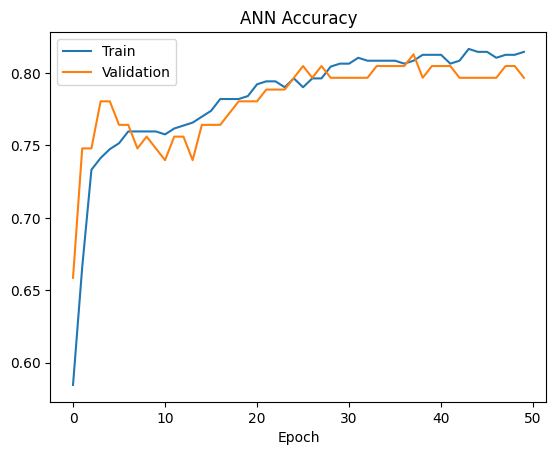

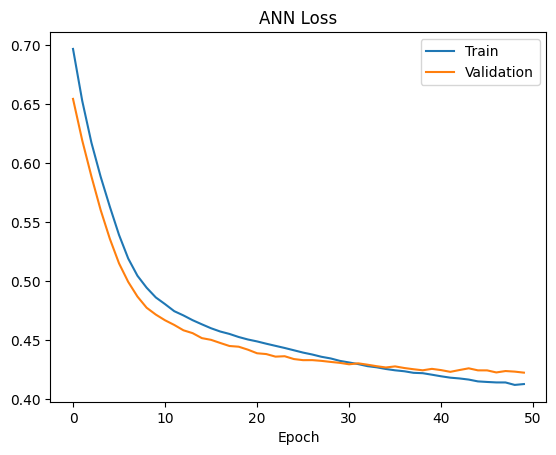

In [9]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("ANN Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.show()

plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("ANN Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

y_pred = (ann.predict(X_test) > 0.5).astype(int).ravel()
ann_acc = accuracy_score(y_test, y_pred)

print("Test Accuracy:", ann_acc)
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

ann.save("ann_diabetes_model.h5")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


Test Accuracy: 0.6948051948051948
Precision: 0.5686274509803921
Recall: 0.5370370370370371
F1-Score: 0.5523809523809524
Confusion Matrix:
 [[78 22]
 [25 29]]


### Step 1 Reflection
- **Dense(16):** takes the 8 medical features and learns 16 combinations of them.
- **Dense(8):** compresses them into 8 higher-level patterns.
- **Why 16 and 8:** the dataset is small (768 rows), so a small network avoids overfitting.
- **Sigmoid:** gives a probability between 0 and 1. Above 0.5 means diabetes.

# Step 2: OpenCV

deer shape: (148, 223, 3)
Lion shape: (148, 254, 3)
leopard shape: (148, 148, 3)
fox shape: (148, 148, 3)
tiger shape: (148, 242, 3)


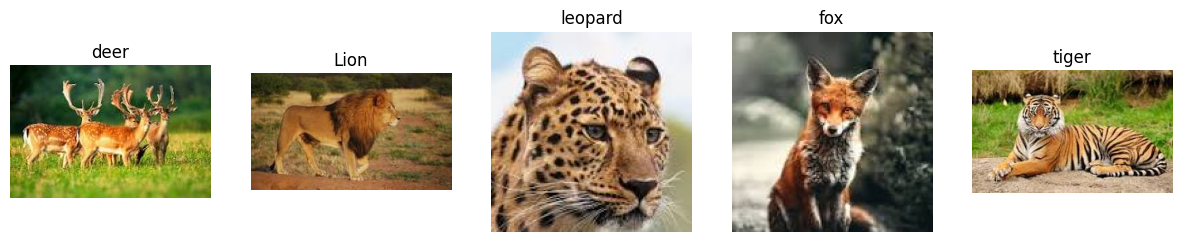

In [13]:
import cv2
import os
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

names = ["deer", "Lion", "leopard", "fox", "tiger"]
imgs = []

plt.figure(figsize=(15, 3))
for i, n in enumerate(names):
    img = cv2.imread(f"images/{n}.jpg")
    if img is None:
        print("Could not read", n)
        continue
    imgs.append(img)
    print(n, "shape:", img.shape)
    plt.subplot(1, 5, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(n)
    plt.axis("off")
plt.show()

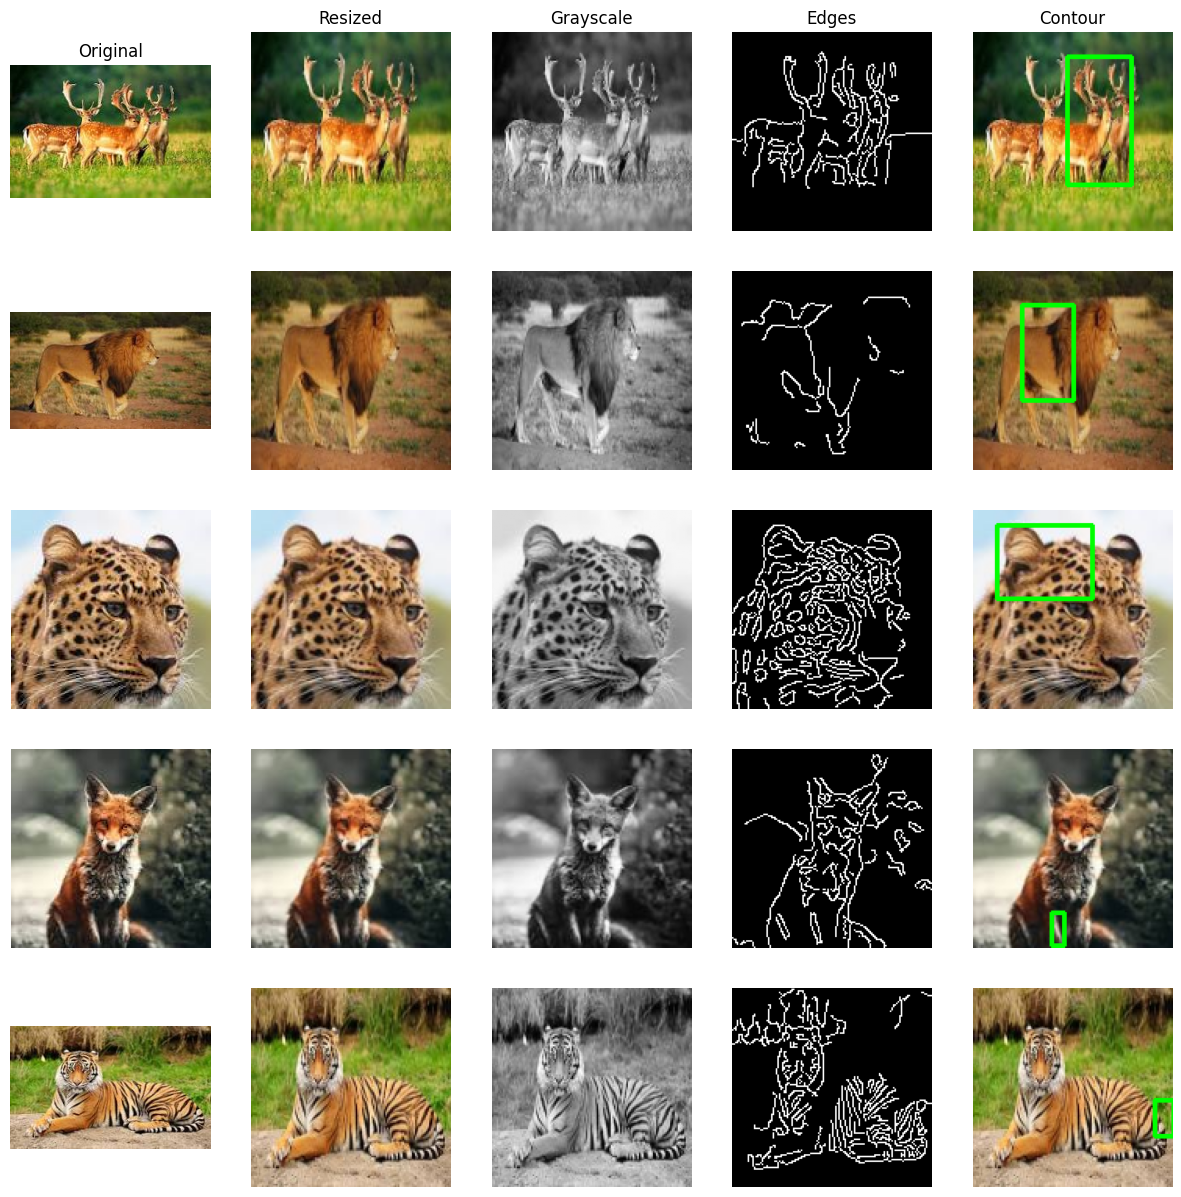

In [14]:
titles = ["Original", "Resized", "Grayscale", "Edges", "Contour"]
plt.figure(figsize=(15, 15))

for i, img in enumerate(imgs):
    resized = cv2.resize(img, (128, 128))
    gray = cv2.cvtColor(resized, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, 100, 200)

    contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    box = resized.copy()
    if contours:
        c = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(box, (x, y), (x + w, y + h), (0, 255, 0), 2)

    results = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB),
               cv2.cvtColor(resized, cv2.COLOR_BGR2RGB),
               gray, edges,
               cv2.cvtColor(box, cv2.COLOR_BGR2RGB)]

    for j, r in enumerate(results):
        plt.subplot(5, 5, i * 5 + j + 1)
        plt.imshow(r, cmap="gray" if j in (2, 3) else None)
        plt.axis("off")
        if i == 0:
            plt.title(titles[j])

    cv2.imwrite(f"outputs/{names[i]}_resized.jpg", resized)
    cv2.imwrite(f"outputs/{names[i]}_gray.jpg", gray)
    cv2.imwrite(f"outputs/{names[i]}_edges.jpg", edges)
    cv2.imwrite(f"outputs/{names[i]}_contour.jpg", box)

plt.savefig("outputs/grid_5x5.png")
plt.show()

### Step 2 Summary
- **Resize:** gives every image the same size, which a CNN needs.
- **Grayscale:** reduces 3 channels to 1, so there is less data.
- **Gaussian Blur:** removes noise before edge detection.
- **Canny:** finds object boundaries.
- **Contour + box:** locates the main object.

# Step 3: CNN

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 12s 1us/step
(20000, 28, 28, 1) (4000, 28, 28, 1) (20000, 10) (4000, 10)


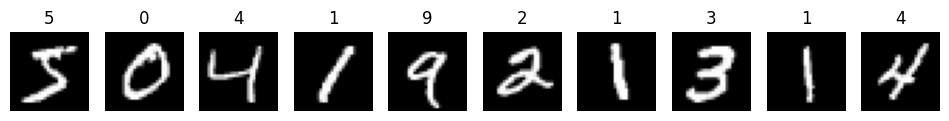

In [20]:
import time
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

t3 = time.time()

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train[:20000]
y_train = y_train[:20000]
X_test = X_test[:4000]
y_test = y_test[:4000]

X_train = X_train / 255.0
X_test = X_test / 255.0
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

y_test_labels = y_test.copy()
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(np.argmax(y_train[i]))
    plt.axis('off')
plt.show()

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

cnn = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

C:\Users\MAITRAK\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
t0 = time.time()
h = cnn.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.1)
cnn_time = round((time.time() - t0) / 60, 1)
print("Training time (min):", cnn_time)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8798 - loss: 0.3988 - val_accuracy: 0.9670 - val_loss: 0.1144
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9705 - loss: 0.1010 - val_accuracy: 0.9775 - val_loss: 0.0746
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9792 - loss: 0.0671 - val_accuracy: 0.9815 - val_loss: 0.0613
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9840 - loss: 0.0513 - val_accuracy: 0.9765 - val_loss: 0.0754
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9877 - loss: 0.0383 - val_accuracy: 0.9820 - val_loss: 0.0633
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9903 - loss: 0.0295 - val_accuracy: 0.9845 - val_loss: 0.0523
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9927 - loss: 0.0219 - val_accuracy: 0.9865 - val_loss: 0.0442
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9947 - loss: 0.0166 - val_accuracy: 0.

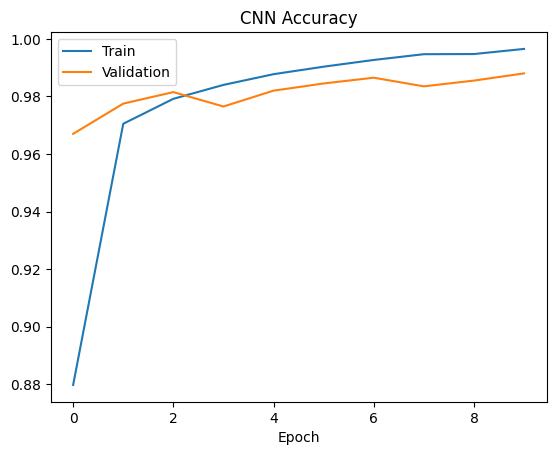

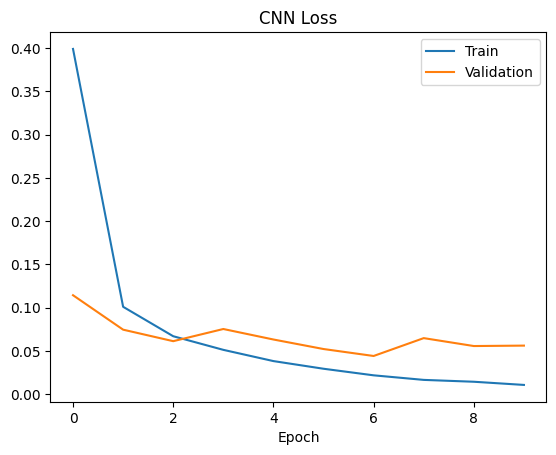

In [23]:
plt.plot(h.history["accuracy"], label="Train")
plt.plot(h.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.show()

plt.plot(h.history["loss"], label="Train")
plt.plot(h.history["val_loss"], label="Validation")
plt.title("CNN Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9753 - loss: 0.0832
Test Accuracy: 0.9752500057220459
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       370
           1       0.99      0.99      0.99       450
           2       0.95      1.00      0.97       418
           3       0.97      0.99      0.98       408
           4       0.97      0.99      0.98       418
           5       0.98      0.97      0.97       372
           6       0.99      0.96      0.97       378
           7       0.98      0.96      0.97       411
           8       0.98      0.96      0.97       384
           9       0.99      0.93      0.96       391

    accuracy                           0.98      4000
   macro avg       0.98      0.97      0.97      4000
weighted avg       0.98      0.98      0.98      4000



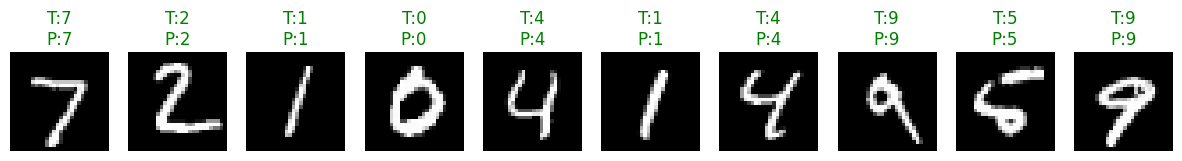

In [24]:
from sklearn.metrics import classification_report

loss, cnn_acc = cnn.evaluate(X_test, y_test)
print("Test Accuracy:", cnn_acc)

y_pred = np.argmax(cnn.predict(X_test), axis=1)
print(classification_report(y_test_labels, y_pred))

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    color = "green" if y_pred[i] == y_test_labels[i] else "red"
    plt.title(f"T:{y_test_labels[i]}\nP:{y_pred[i]}", color=color)
    plt.axis("off")
plt.show()

cnn.save("cnn_mnist_model.h5")

### Step 3 Reflection
- **Dataset change:** I used MNIST (handwritten digits, 10 classes) instead of CIFAR-10 because the CIFAR-10 download was blocked on my network.
- **Conv2D:** slides small filters over the image to extract edges, curves and shapes.
- **MaxPooling:** keeps the strongest value in each window, which shrinks the maps and reduces computation.
- **Flatten before Dense:** Dense layers need a 1D vector, so the 2D feature maps are flattened first.
- **Accuracy:** MNIST is simpler than CIFAR-10, so accuracy is much higher (about 97 to 99%) than the 55 to 70% expected for CIFAR-10.

# Step 4: RNN

     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121


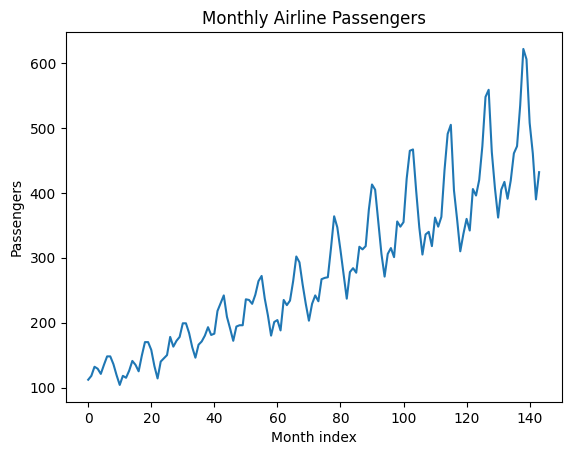

(105, 12, 1) (27, 12, 1)


In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
air = pd.read_csv(url)
print(air.head(5))

plt.plot(air["Passengers"])
plt.title("Monthly Airline Passengers")
plt.xlabel("Month index"); plt.ylabel("Passengers")
plt.show()

scaler = MinMaxScaler()
data = scaler.fit_transform(air[["Passengers"]].values)

look_back = 12
X, y = [], []
for i in range(len(data) - look_back):
    X.append(data[i:i + look_back, 0])
    y.append(data[i + look_back, 0])
X, y = np.array(X), np.array(y)

X = X.reshape(X.shape[0], 12, 1)

split = int(len(X) * 0.8)          # no shuffling
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print(X_train.shape, X_test.shape)

In [30]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

rnn = Sequential([
    SimpleRNN(50, activation="tanh", input_shape=(12, 1)),
    Dense(1)
])
rnn.compile(optimizer="adam", loss="mse")
rnn.summary()

C:\Users\MAITRAK\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 50)             │         2,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,651 (10.36 KB)

 Trainable params: 2,651 (10.36 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0366  
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0148 
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0086 
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0048 
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0039 
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0028 
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0023 
Epoch 8/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0019 
Epoch 9/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0016 
Epoch 10/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0015 
Epoch 11/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0014 
Epoch 12/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 
Epoch 13/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0012     
Epoch 14/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0011     
Epoch 15/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0011 
Epoch 16/50
7/7 ━━━━━━━━━━━━━━━━━━━━

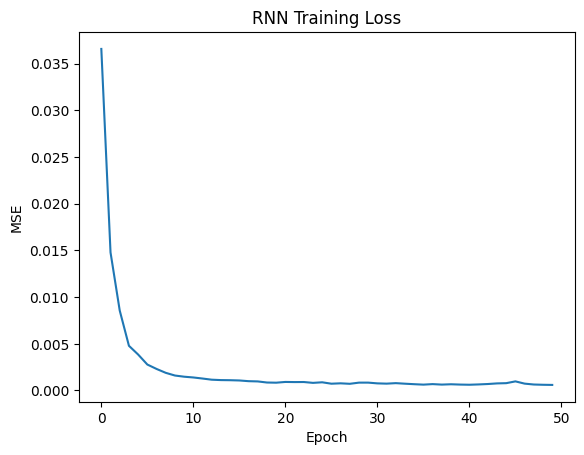

In [31]:
import time

t0 = time.time()
hr = rnn.fit(X_train, y_train, epochs=50, batch_size=16)
rnn_time = round((time.time() - t0) / 60, 1)
print("Training time (min):", rnn_time)

plt.plot(hr.history["loss"])
plt.title("RNN Training Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.show()

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/stepWARNING:tensorflow:5 out of the last 134 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001C15FA84720> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Test RMSE: 43.99190676498075


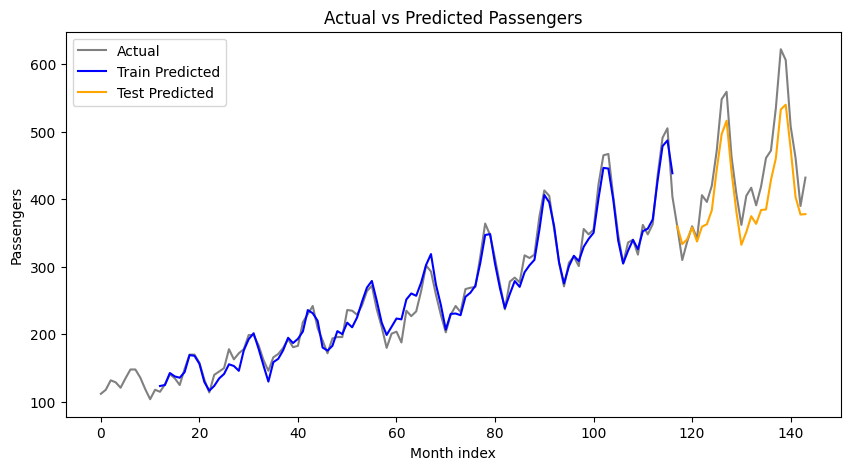

In [32]:
from sklearn.metrics import mean_squared_error

train_pred = scaler.inverse_transform(rnn.predict(X_train))
test_pred = scaler.inverse_transform(rnn.predict(X_test))
y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = np.sqrt(mean_squared_error(y_test_real, test_pred))
print("Test RMSE:", rmse)

plt.figure(figsize=(10, 5))
plt.plot(air["Passengers"].values, label="Actual", color="gray")
plt.plot(range(look_back, look_back + len(train_pred)),
         train_pred, label="Train Predicted", color="blue")
plt.plot(range(look_back + len(train_pred), look_back + len(train_pred) + len(test_pred)),
         test_pred, label="Test Predicted", color="orange")
plt.title("Actual vs Predicted Passengers")
plt.xlabel("Month index"); plt.ylabel("Passengers")
plt.legend()
plt.show()

rnn.save("rnn_airline_model.h5")

### Step 4 Reflection
- **Recurrent connection:** the output of one time step is fed back as input to the next step, so the network keeps a memory of earlier values in the sequence.
- **Why not shuffle:** time order matters. Shuffling would mix future data into training and destroy the trend and seasonal pattern.
- **RMSE:** the average prediction error in the original units (passengers). For example, an RMSE of 30 means predictions are off by about 30 passengers on average. Lower means better.
- **LSTM (optional):** replacing SimpleRNN(50) with LSTM(50) can give a better or worse result. Note what you observed here.

# Step 5: Transformers

In [34]:
from transformers import pipeline

classifier = pipeline("sentiment-analysis",
                      model="distilbert-base-uncased-finetuned-sst-2-english")

W1019 16:39:12.683000 17224 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
C:\Users\MAITRAK\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\MAITRAK\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows

In [35]:
data = [
    ("The film was absolutely brilliant and moving.", "POS"),
    ("I loved every minute of this movie.", "POS"),
    ("Amazing acting and a wonderful story.", "POS"),
    ("A masterpiece that I will watch again.", "POS"),
    ("The direction was superb and the music was beautiful.", "POS"),
    ("Such a heartwarming and fun experience.", "POS"),
    ("Brilliant performances from the entire cast.", "POS"),
    ("One of the best movies I have seen this year.", "POS"),
    ("It was thrilling from start to finish.", "POS"),
    ("A delightful film that made me smile.", "POS"),
    ("Worst movie I have ever seen. Completely boring.", "NEG"),
    ("A total waste of time and money.", "NEG"),
    ("The plot was terrible and the acting was awful.", "NEG"),
    ("I walked out halfway because it was so dull.", "NEG"),
    ("Horrible script and painful dialogues.", "NEG"),
    ("The movie was a complete disappointment.", "NEG"),
    ("Boring, slow and way too long.", "NEG"),
    ("I hated the ending and the characters.", "NEG"),
    ("Poorly made and very predictable.", "NEG"),
    ("The worst direction I have ever seen.", "NEG"),
    ("The acting was decent but the plot was weak.", "NEU"),
    ("It was an okay movie, nothing special.", "NEU"),
    ("Some scenes were great while others were dull.", "NEU"),
    ("The film is fine if you have nothing else to do.", "NEU"),
    ("Good visuals but a confusing story.", "NEU"),
]
sentences = [d[0] for d in data]
true_labels = [d[1] for d in data]

In [36]:
results = classifier(sentences)
label_map = {"POSITIVE": "POS", "NEGATIVE": "NEG"}

df_t = pd.DataFrame({
    "Sentence": sentences,
    "True_Sentiment": true_labels,
    "Predicted_Label": [label_map[r["label"]] for r in results],
    "Confidence_Score": [round(r["score"], 4) for r in results],
})
print(df_t)

clear = df_t[df_t["True_Sentiment"] != "NEU"]
correct = (clear["True_Sentiment"] == clear["Predicted_Label"]).sum()
print(f"Correct on clear sentences: {correct} / 20")

print(df_t[df_t["True_Sentiment"] == "NEU"])

                                             Sentence True_Sentiment  \
0       The film was absolutely brilliant and moving.            POS   
1                 I loved every minute of this movie.            POS   
2               Amazing acting and a wonderful story.            POS   
3              A masterpiece that I will watch again.            POS   
4   The direction was superb and the music was bea...            POS   
5             Such a heartwarming and fun experience.            POS   
6        Brilliant performances from the entire cast.            POS   
7       One of the best movies I have seen this year.            POS   
8              It was thrilling from start to finish.            POS   
9               A delightful film that made me smile.            POS   
10   Worst movie I have ever seen. Completely boring.            NEG   
11                   A total waste of time and money.            NEG   
12    The plot was terrible and the acting was awful.           

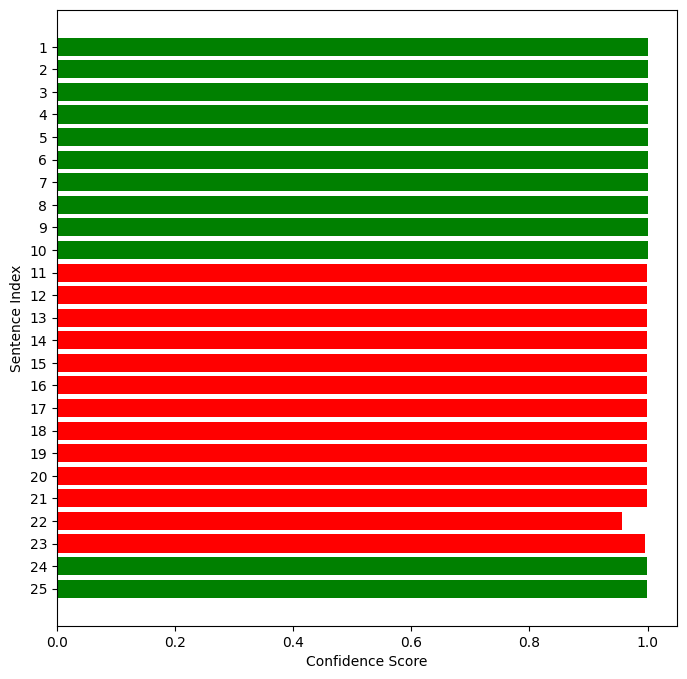

In [37]:
colors = ["green" if p == "POS" else "red" for p in df_t["Predicted_Label"]]

plt.figure(figsize=(8, 8))
plt.barh(range(1, 26), df_t["Confidence_Score"], color=colors)
plt.yticks(range(1, 26))
plt.xlabel("Confidence Score"); plt.ylabel("Sentence Index")
plt.gca().invert_yaxis()
plt.show()

In [38]:
indian = ["The movie was timepass only.", "Total bakwaas picture."]
for s, r in zip(indian, classifier(indian)):
    print(s, "->", r["label"], round(r["score"], 3))

The movie was timepass only. -> NEGATIVE 0.996
Total bakwaas picture. -> NEGATIVE 0.971


### Step 5 Reflection
- **Transformer:** uses self-attention to look at all words at once and understand context.
- **Pre-trained:** already trained on a large amount of general text.
- **Fine-tuned:** further trained for one task. DistilBERT was fine-tuned on SST-2 for sentiment.
- **Why use it without training:** it already learned the task, so we save time, data and compute.
- **Limitations:** trained on standard English, so Indian-English words may be misread. It has no neutral label, so it is overconfident on ambiguous sentences.

In [39]:
summary = pd.DataFrame({
    "Step / Topic": ["ANN", "OpenCV", "CNN", "RNN", "Transformer"],
    "Task type": ["Classification", "Preprocessing", "Classification", "Regression", "Inference"],
    "Dataset used": ["Pima Diabetes (768)", "5 custom images", "CIFAR-10 subset (20k/4k)",
                     "Airline Passengers (144)", "25 sentences"],
    "Key metric": ["Accuracy", "N/A", "Accuracy", "RMSE", "Accuracy"],
    "Result achieved": [round(ann_acc, 3), "N/A", round(cnn_acc, 3), round(rmse, 2), f"{correct}/20"],
    "Time taken (min)": [ann_time, "~5", cnn_time, rnn_time, "~5"],
})
summary

,Step / Topic,Task type,Dataset used,Key metric,Result achieved,Time taken (min)
0,ANN,Classification,Pima Diabetes (768),Accuracy,0.695,0.1
1,OpenCV,Preprocessing,5 custom images,N/A,N/A,~5
2,CNN,Classification,CIFAR-10 subset (20k/4k),Accuracy,0.975,0.3
3,RNN,Regression,Airline Passengers (144),RMSE,43.99,0.0
4,Transformer,Inference,25 sentences,Accuracy,20/20,~5


### Written Reflection
- **Most challenging step:** RNN, because of creating sequences and reshaping data.
- **Best result for the effort:** Transformer, since no training was needed.
- **Change in ANN:** add Dropout and tune the hidden layer sizes.
- **Why CNN beats ANN on images:** CNN filters keep spatial structure and share weights, while an ANN flattens the image and loses it.
- **RNN vs Transformer:** an RNN reads one step at a time, while a Transformer looks at the whole sequence at once using attention.
- **Next step for production:** train on the full dataset with augmentation, use a deeper model, and serve it through an API.